In [181]:
#ОЧИСТКА ДАННЫХ 
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact
import pandas as pd
import numpy as np


df= pd.read_csv('olympiad_results.csv')

dictionary= pd.read_csv('olympiad_data_dictionary.csv')


print("Размер таблицы:", df.shape)

df = df.dropna(how='all')

print("Все города в таблице:")
print(df['region'].unique())


df.head(10)
print(df.shape)


print("Дубликатов до очистки:", df.duplicated().sum())

df = df.drop_duplicates()


df['region'] = df['region'].str.replace('г.', '', regex=False)
city_mapping={
    'мск': 'Москва',
    'москва': 'Москва',
    'спб': 'Санкт-Петербург',
    'Moskva': 'Москва',
    'СПб': 'Санкт-Петербург',
    'казань': 'Казань',
    'Санкт Петербург': 'Санкт-Петербург'
}
    
df['region'] = df['region'].replace(city_mapping)

df['region'] = df['region'].str.strip()


print("Города после очистки:")
print(df['region'].unique())


df = df[df['student_id'] != 0]
df = df[df['student_id'] != 99999]


print(" Статистика по времени ")

if 'start_time' in df.columns and 'end_time' in df.columns:
    df['start'] = pd.to_datetime(df['start_time'])
    df['end'] = pd.to_datetime(df['end_time'])
    df['dur'] = (df['end'] - df['start']).dt.total_seconds() / 60
   

df = df[df['dur'] >=5] #больше 5 минут выполнение 


print(df['dur'].describe())

df.describe()
df.shape


Размер таблицы: (8037, 46)
Все города в таблице:
<StringArray>
[      'Краснодар',  'Ростов-на-Дону',    'Екатеринбург',          'Казань',
             'Уфа', 'Санкт-Петербург',     'Новосибирск',         'Воронеж',
           'Пермь',             'мск',          'москва',          'Москва',
        'г.Казань',       'г. Москва', 'Санкт Петербург',          'Moskva',
             'СПб',             'спб',          'казань']
Length: 19, dtype: str
(8037, 46)
Дубликатов до очистки: 37
Города после очистки:
<StringArray>
[      'Краснодар',  'Ростов-на-Дону',    'Екатеринбург',          'Казань',
             'Уфа', 'Санкт-Петербург',     'Новосибирск',         'Воронеж',
           'Пермь',          'Москва']
Length: 10, dtype: str
 Статистика по времени 
count    7928.000000
mean       14.121168
std         1.634766
min         7.833333
25%        13.033333
50%        14.150000
75%        15.233333
max        19.566667
Name: dur, dtype: float64


(7928, 49)

В 1ой секции я проанализировала данные таблицы и профильтровала их: убрала дубликаты и аномальные сессии 

In [165]:
#Среднее время на задание для каждого ученика (по строкам) И  Среднее время по каждому заданию (по всем ученикам)
time_cols = [col for col in df.columns if '_time_spent' in col]

df_time_minutes = df[time_cols]/60


df_time_minutes = df_time_minutes.replace(0, np.nan)
df['avg_time_per_task_min'] = df_time_minutes.mean(axis=1).round(2)


avg_time_by_task = df_time_minutes.mean(axis=0).round(2)

print("Среднее время решения каждого задания (минуты) ")
print(avg_time_by_task)


print(f"   Минимум: {df['total_score'].min()}")
print(f"   Максимум: {df['total_score'].max()}")
print(f"   Средний: {df['total_score'].mean():.2f}")



Среднее время решения каждого задания (минуты) 
Task_1_time_spent     1.07
Task_2_time_spent     1.15
Task_3_time_spent     1.10
Task_4_time_spent     1.31
Task_5_time_spent     1.35
Task_6_time_spent     1.20
Task_7_time_spent     1.32
Task_8_time_spent     1.33
Task_9_time_spent     1.10
Task_10_time_spent    1.26
Task_11_time_spent    1.21
Task_12_time_spent    1.30
dtype: float64
   Минимум: 0
   Максимум: 12
   Средний: 5.55


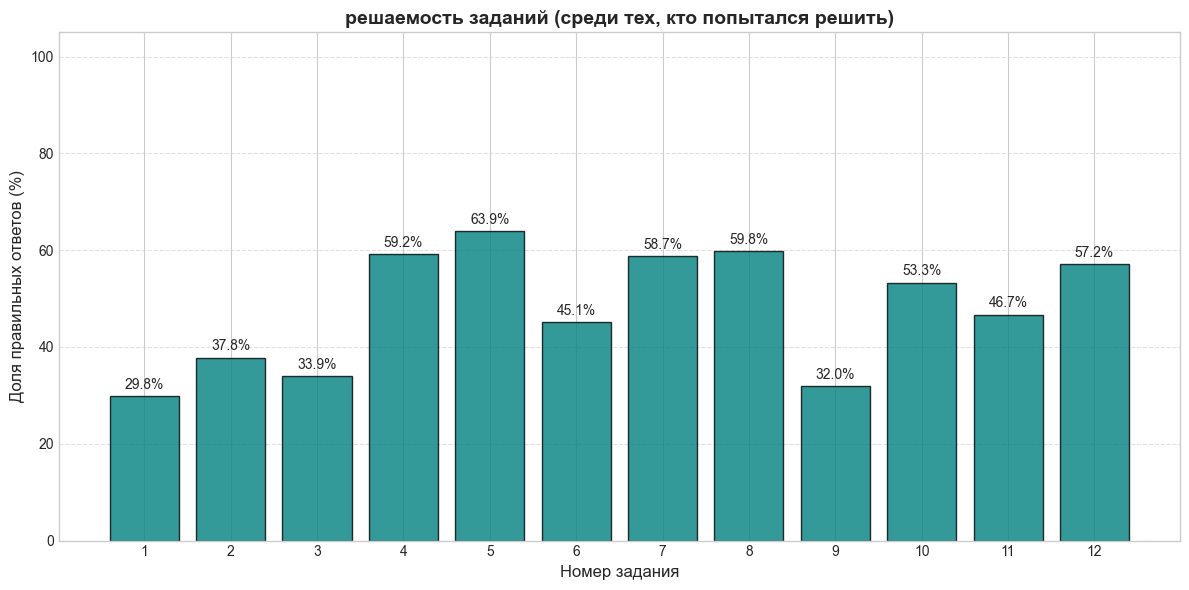

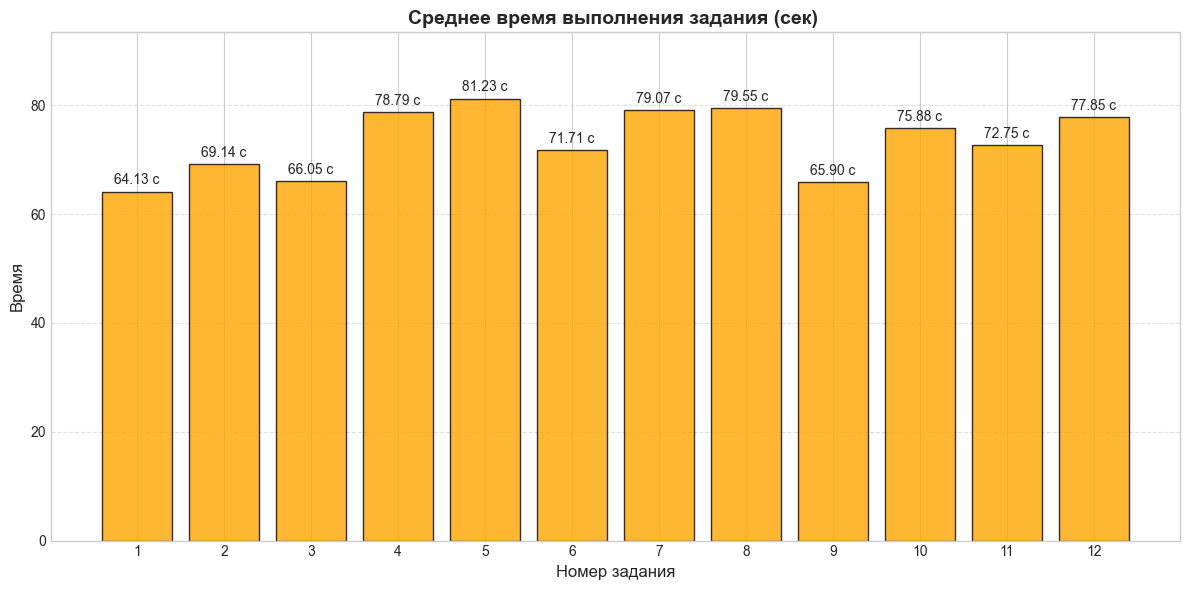

In [193]:
#сложность заданий 4 пункт СРЕДНЕЕ ВРЕМЯ РЕШЕНИЯ И ПРОЦЕНТ РЕШЕННОСТИ 


task_numbers = list(range(1, 13))
honest_solve_rates = []
attempt_counts = []


for i in task_numbers:
    time_col = f'Task_{i}_time_spent'
    correct_col = f'Task_{i}_correct'
    
    attempted = df[df[time_col] > 0]
    
    
    count = len(attempted)
    attempt_counts.append(count)
    if count > 0:
        rate = (attempted[correct_col].mean() * 100).round(1)
    else:
        rate = 0.0
        
    honest_solve_rates.append(rate)


plt.figure(figsize=(12, 6))

bars = plt.bar(task_numbers, honest_solve_rates, color='teal', edgecolor='black', alpha=0.8)

plt.bar_label(bars, padding=3, fontsize=10, fmt='%.1f%%')

plt.title('решаемость заданий (среди тех, кто попытался решить)', fontsize=14, fontweight='bold')
plt.xlabel('Номер задания', fontsize=12)
plt.ylabel('Доля правильных ответов (%)', fontsize=12)
plt.xticks(task_numbers)
plt.ylim(0, 105) 
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()




task_numbers = list(range(1, 13))
avg_times = []

for i in task_numbers:
    col = f'Task_{i}_time_spent'
    attempted = df[df[col] > 0.1]
    
    if len(attempted) > 0:
        avg_time = attempted[col].mean()
        avg_times.append(avg_time)
    else:
        avg_times.append(0)


plt.figure(figsize=(12, 6))
bars = plt.bar(task_numbers, avg_times, color='orange', edgecolor='black', alpha=0.8)
plt.bar_label(bars, padding=3, fontsize=10, fmt='%.2f с')

plt.title('Среднее время выполнения задания (сек) ', fontsize=14, fontweight='bold')
plt.xlabel('Номер задания', fontsize=12)
plt.ylabel('Время', fontsize=12)
plt.xticks(task_numbers)
plt.ylim(0, max(avg_times) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

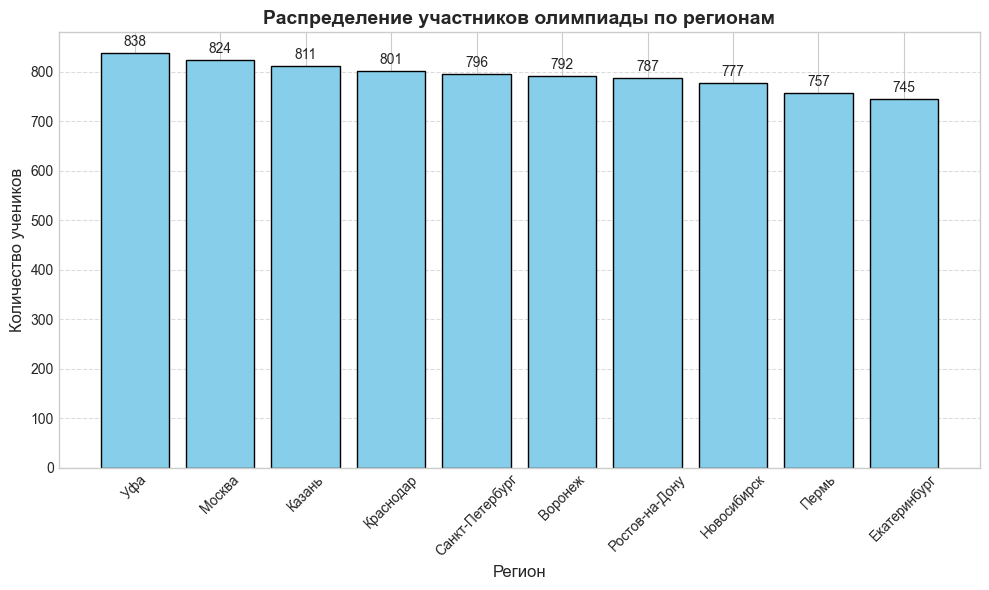

In [154]:
#5 Описать аудиторию олимпиады: построить распределение участников по классам, школам и регионам

plt.figure(figsize=(10, 6))


region_counts = df['region'].value_counts()

bars = plt.bar(region_counts.index, region_counts.values, color='skyblue', edgecolor='black')

plt.bar_label(bars, padding=3, fontsize=10)

plt.title('Распределение участников олимпиады по регионам', fontsize=14, fontweight='bold')
plt.xlabel('Регион', fontsize=12)
plt.ylabel('Количество учеников', fontsize=12)
plt.xticks(rotation=45) 
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

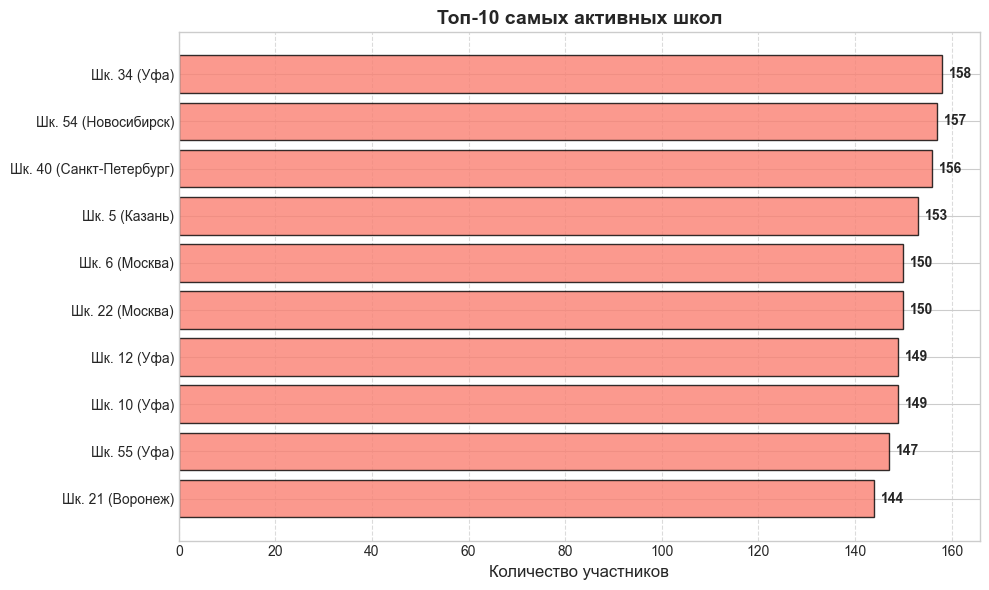

In [184]:

# ТОП-10 активных школ

school_stats = df.groupby('school_number').agg(
    participants=('student_id', 'count'),          
    region=('region', lambda x: x.mode()[0]),       
    avg_score=('total_score', 'mean')               
).reset_index()

school_stats = school_stats.sort_values('participants', ascending=False)


top_10_schools = school_stats.head(10).copy()

plt.figure(figsize=(10, 6))


labels = [f"Шк. {int(row['school_number'])} ({row['region']})" 
          for _, row in top_10_schools.iterrows()]

bars = plt.barh(range(len(labels)), top_10_schools['participants'], 
                color='salmon', edgecolor='black', alpha=0.8)

plt.bar_label(bars, padding=5, fontsize=10, fontweight='bold')

plt.yticks(range(len(labels)), labels, fontsize=10)
plt.gca().invert_yaxis()

plt.title('Топ-10 самых активных школ', fontsize=14, fontweight='bold')
plt.xlabel('Количество участников', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

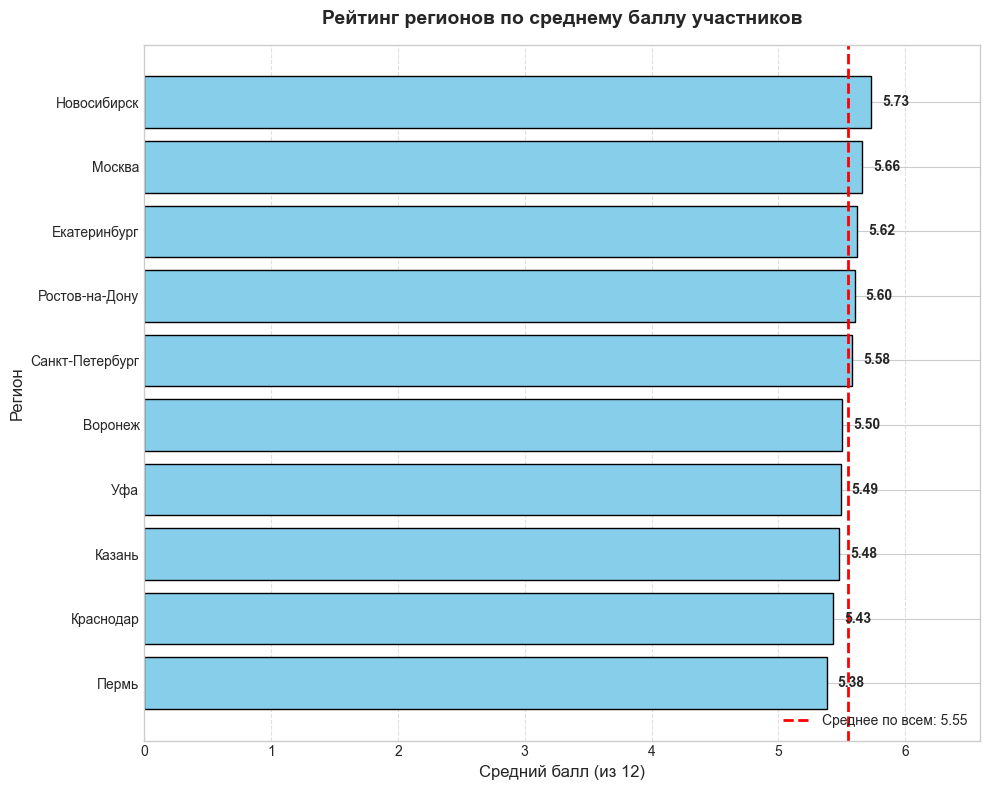

In [164]:
#РЕЙТИНГ РЕГИОНОВ ПО СРЕДНЕМУ БАЛЛУ 


region_scores = df.groupby('region')['total_score'].mean().reset_index()
region_scores = region_scores.sort_values(by='total_score', ascending=False).reset_index(drop=True)


region_scores['Место'] = region_scores.index + 1

overall_avg = region_scores['total_score'].mean()


plt.figure(figsize=(10, 8)) 

bars = plt.barh(rating_table['Регион'], rating_table['Средний балл'], color='skyblue', edgecolor='black')


plt.gca().invert_yaxis()
plt.bar_label(bars, padding=8, fmt='%.2f', fontsize=10, fontweight='bold')

plt.axvline(overall_avg, color='red', linestyle='--', linewidth=2, label=f'Среднее по всем: {overall_avg:.2f}')


plt.title('Рейтинг регионов по среднему баллу участников', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Средний балл (из 12)', fontsize=12)
plt.ylabel('Регион', fontsize=12)


plt.xlim(0, rating_table['Средний балл'].max() * 1.15)

plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()

АНАЛИЗ РЕГИОНА: ВОРОНЕЖ
 Всего участников: 792


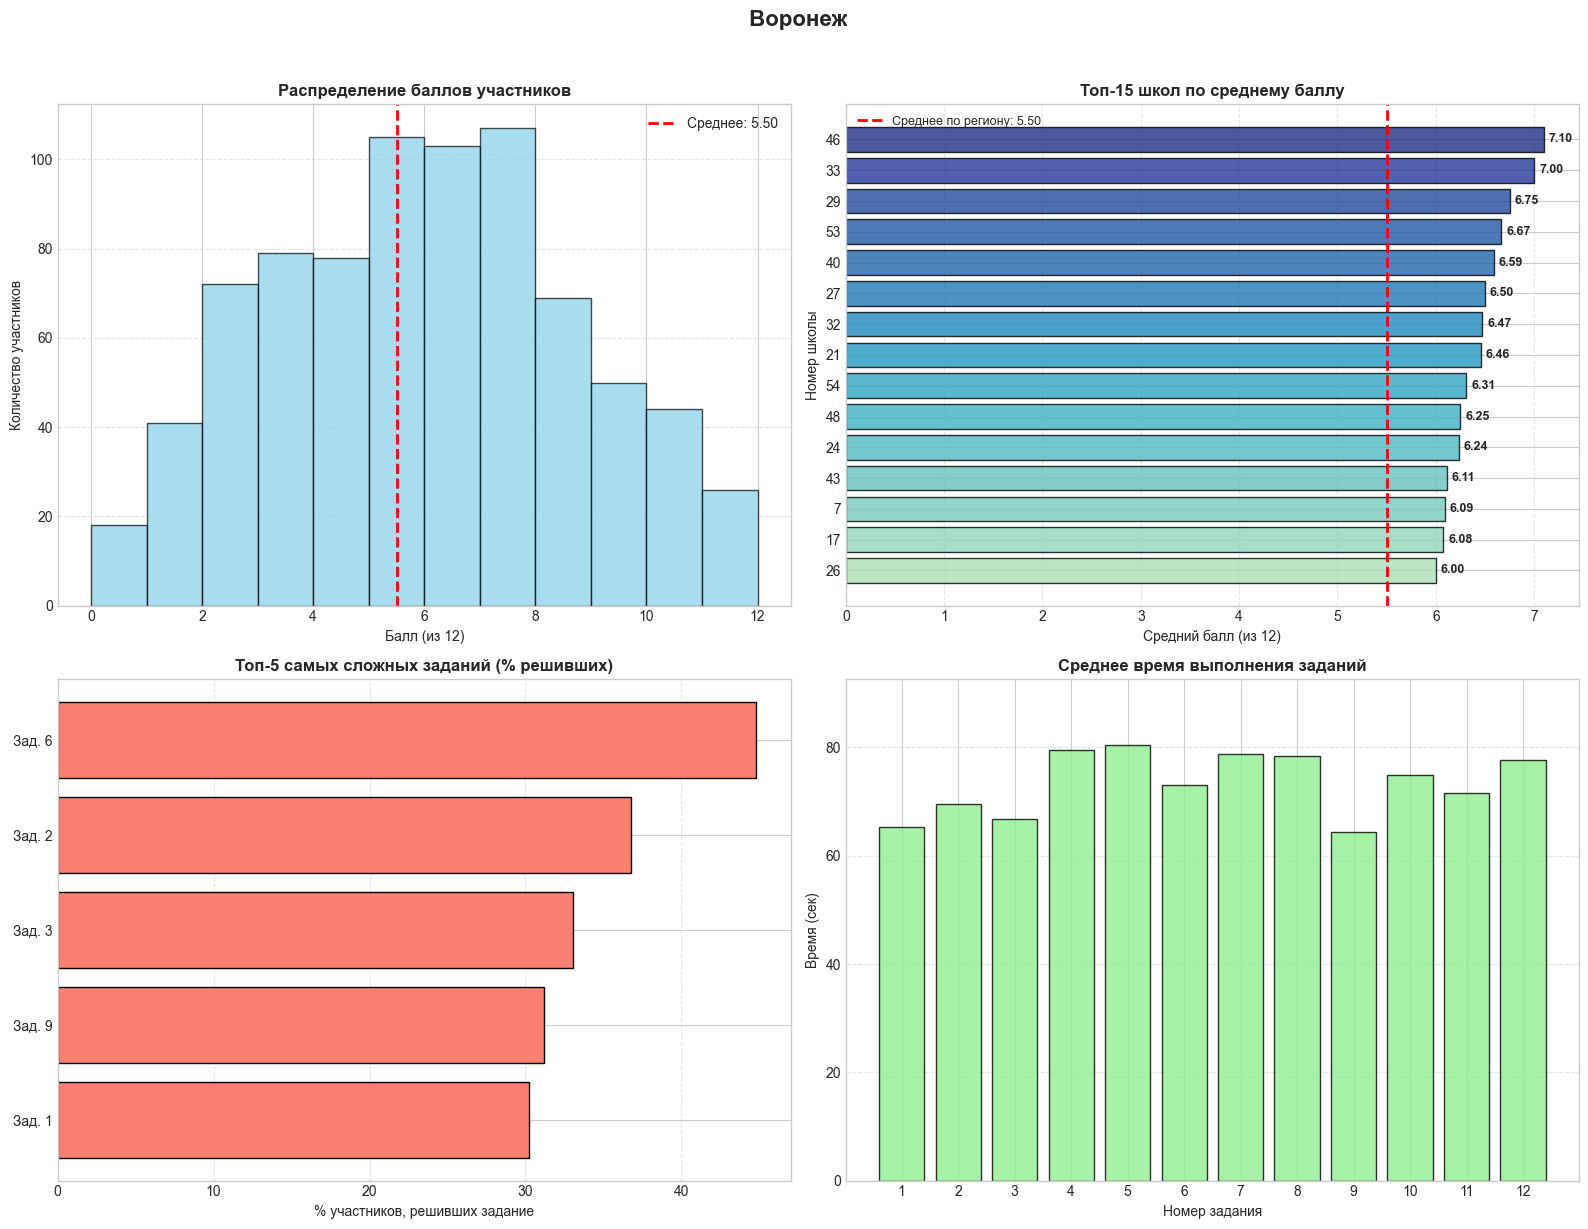

АНАЛИЗ РЕГИОНА: ЕКАТЕРИНБУРГ
 Всего участников: 745


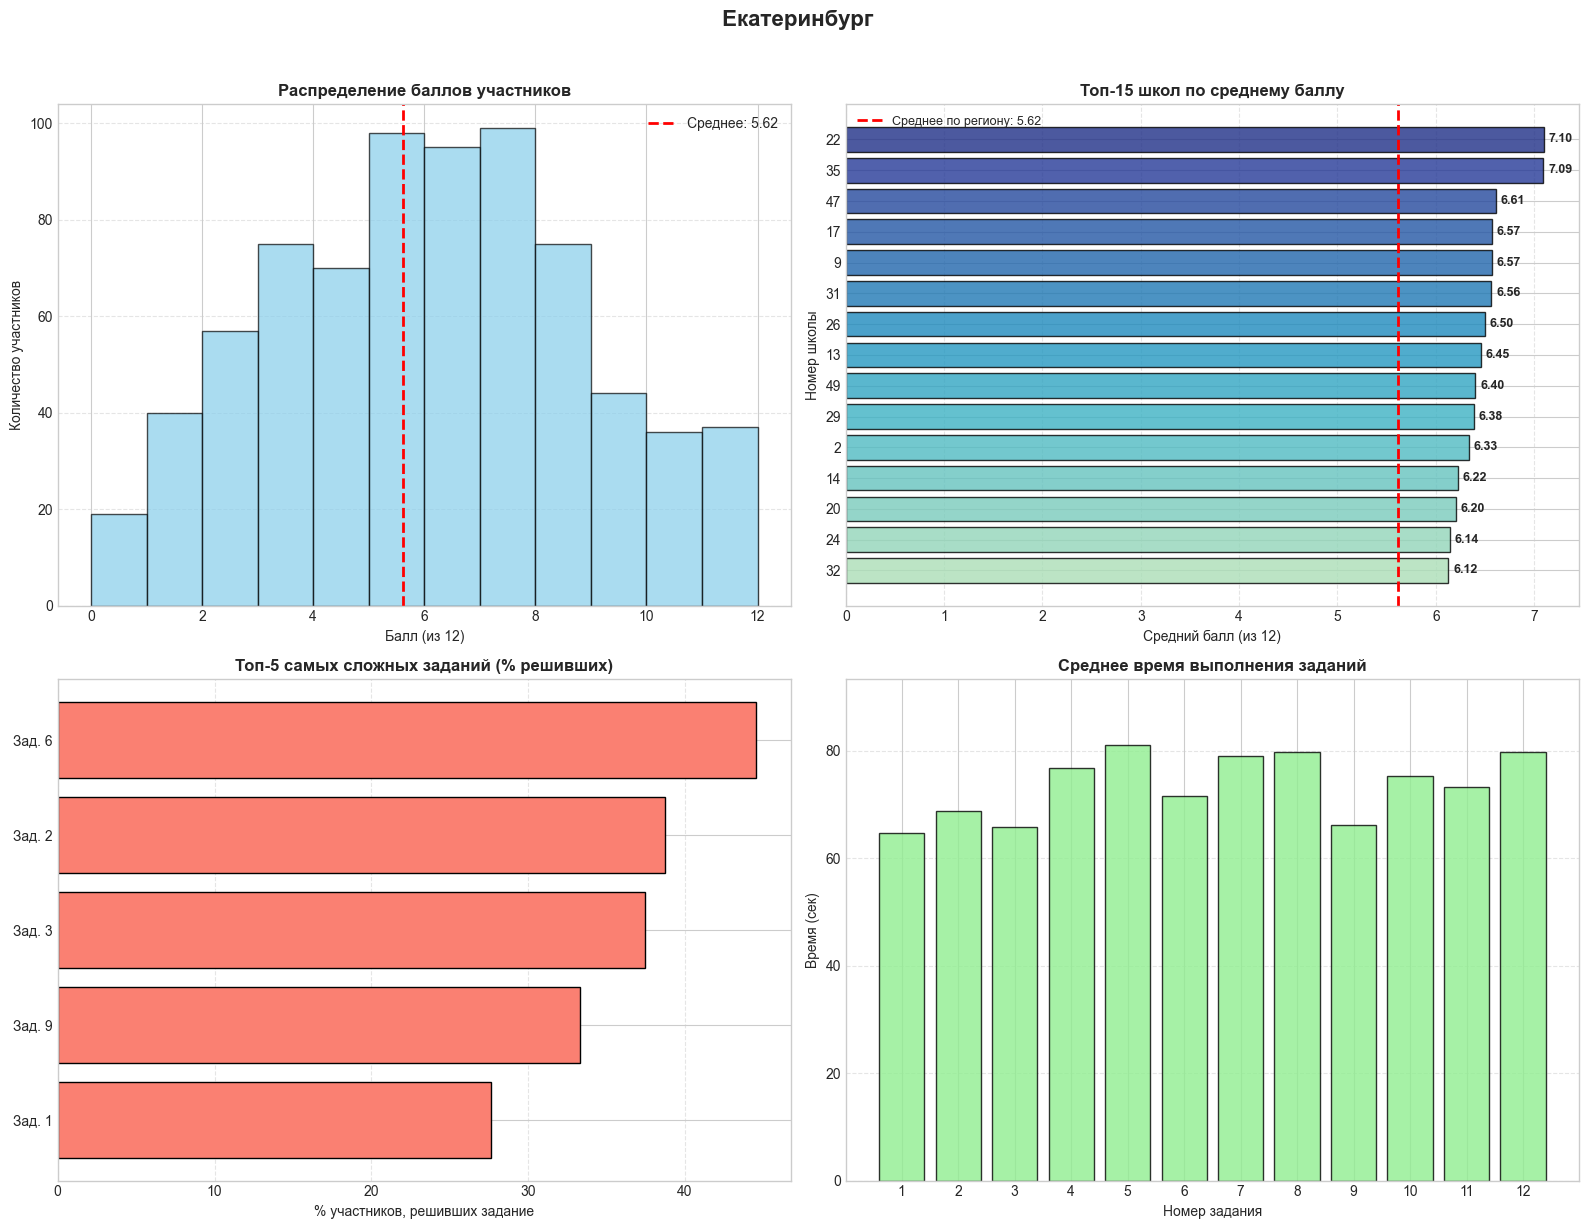

АНАЛИЗ РЕГИОНА: КАЗАНЬ
 Всего участников: 811


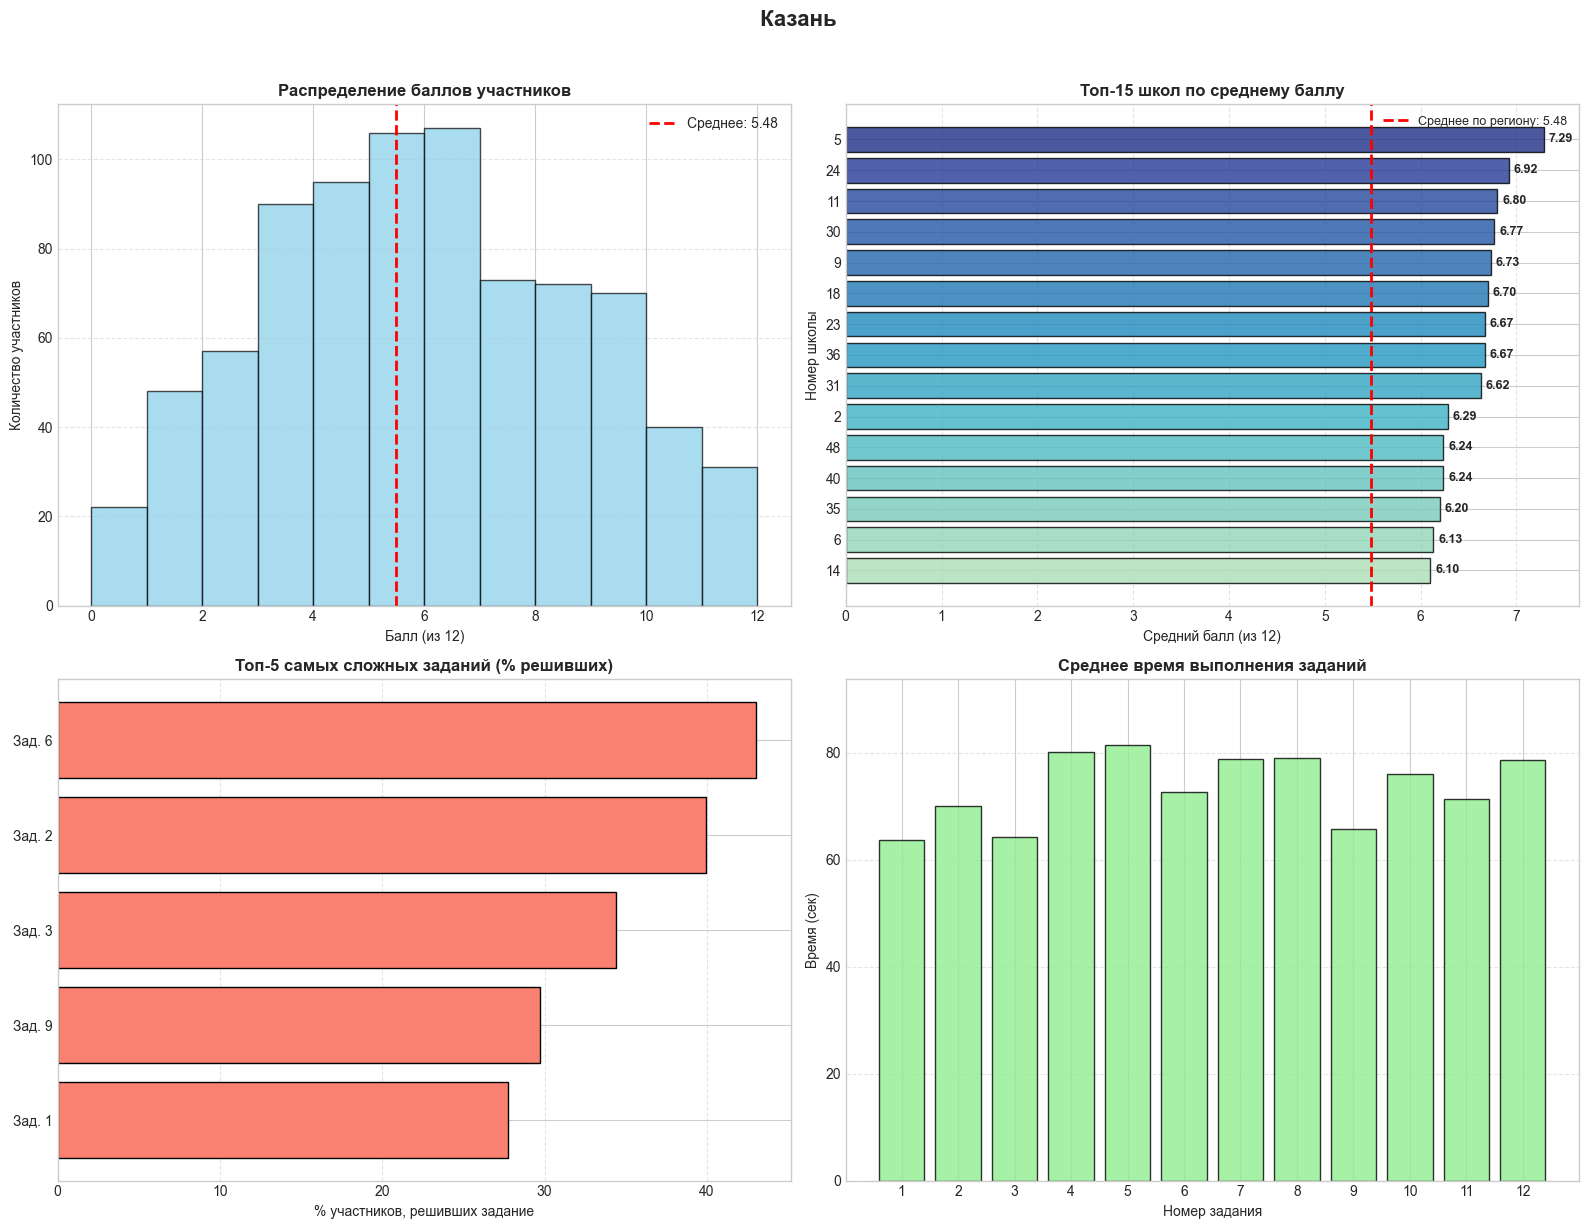

АНАЛИЗ РЕГИОНА: КРАСНОДАР
 Всего участников: 801


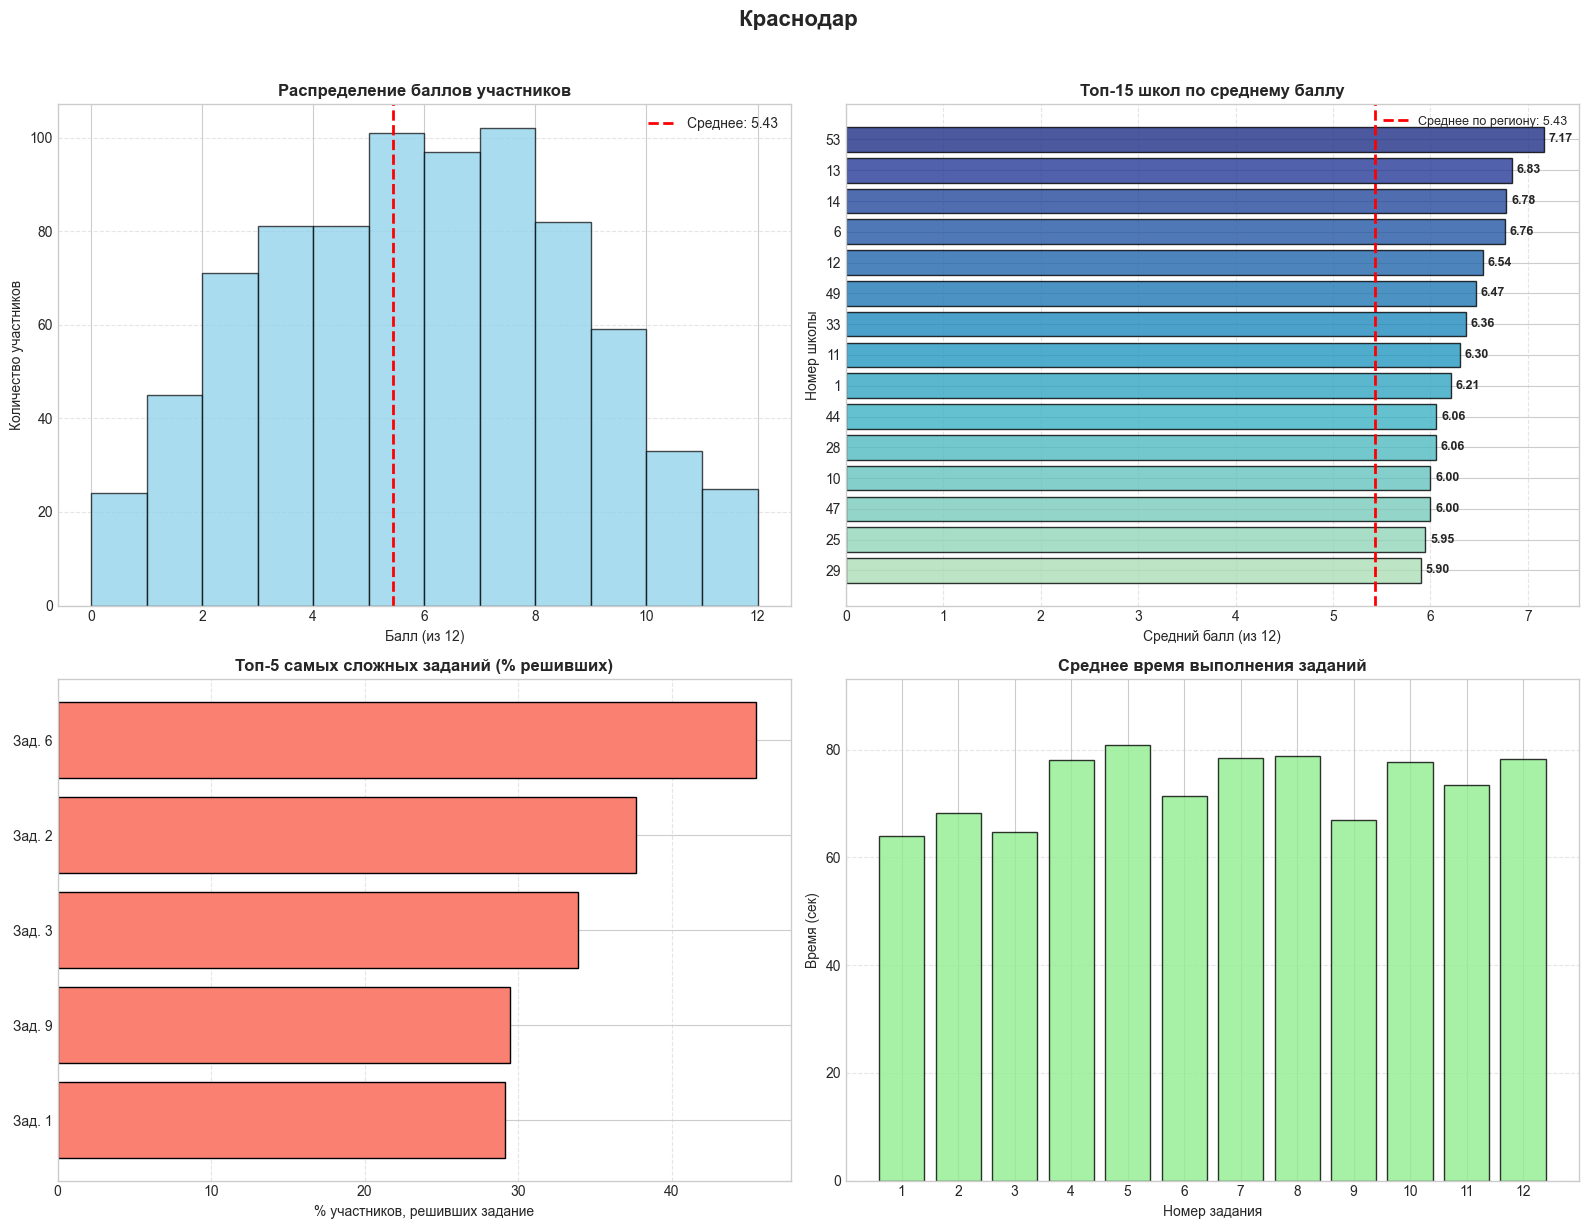

АНАЛИЗ РЕГИОНА: МОСКВА
 Всего участников: 824


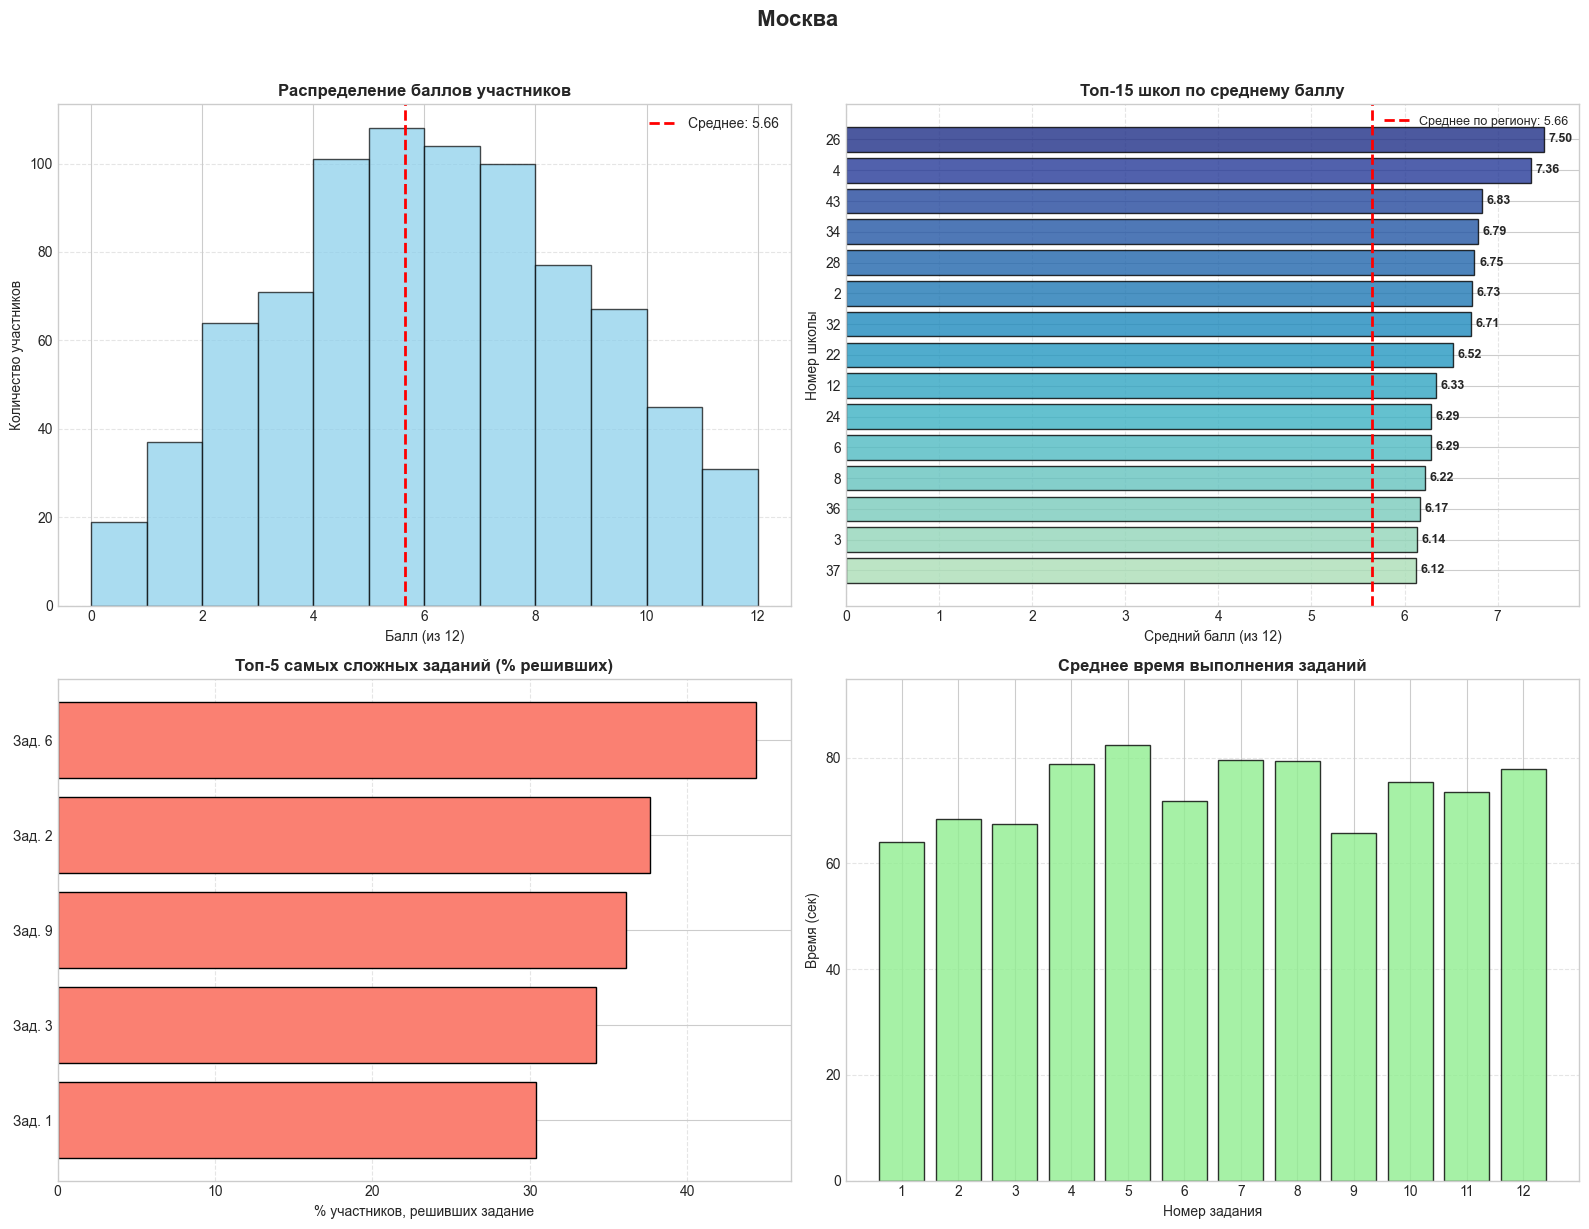

АНАЛИЗ РЕГИОНА: НОВОСИБИРСК
 Всего участников: 777


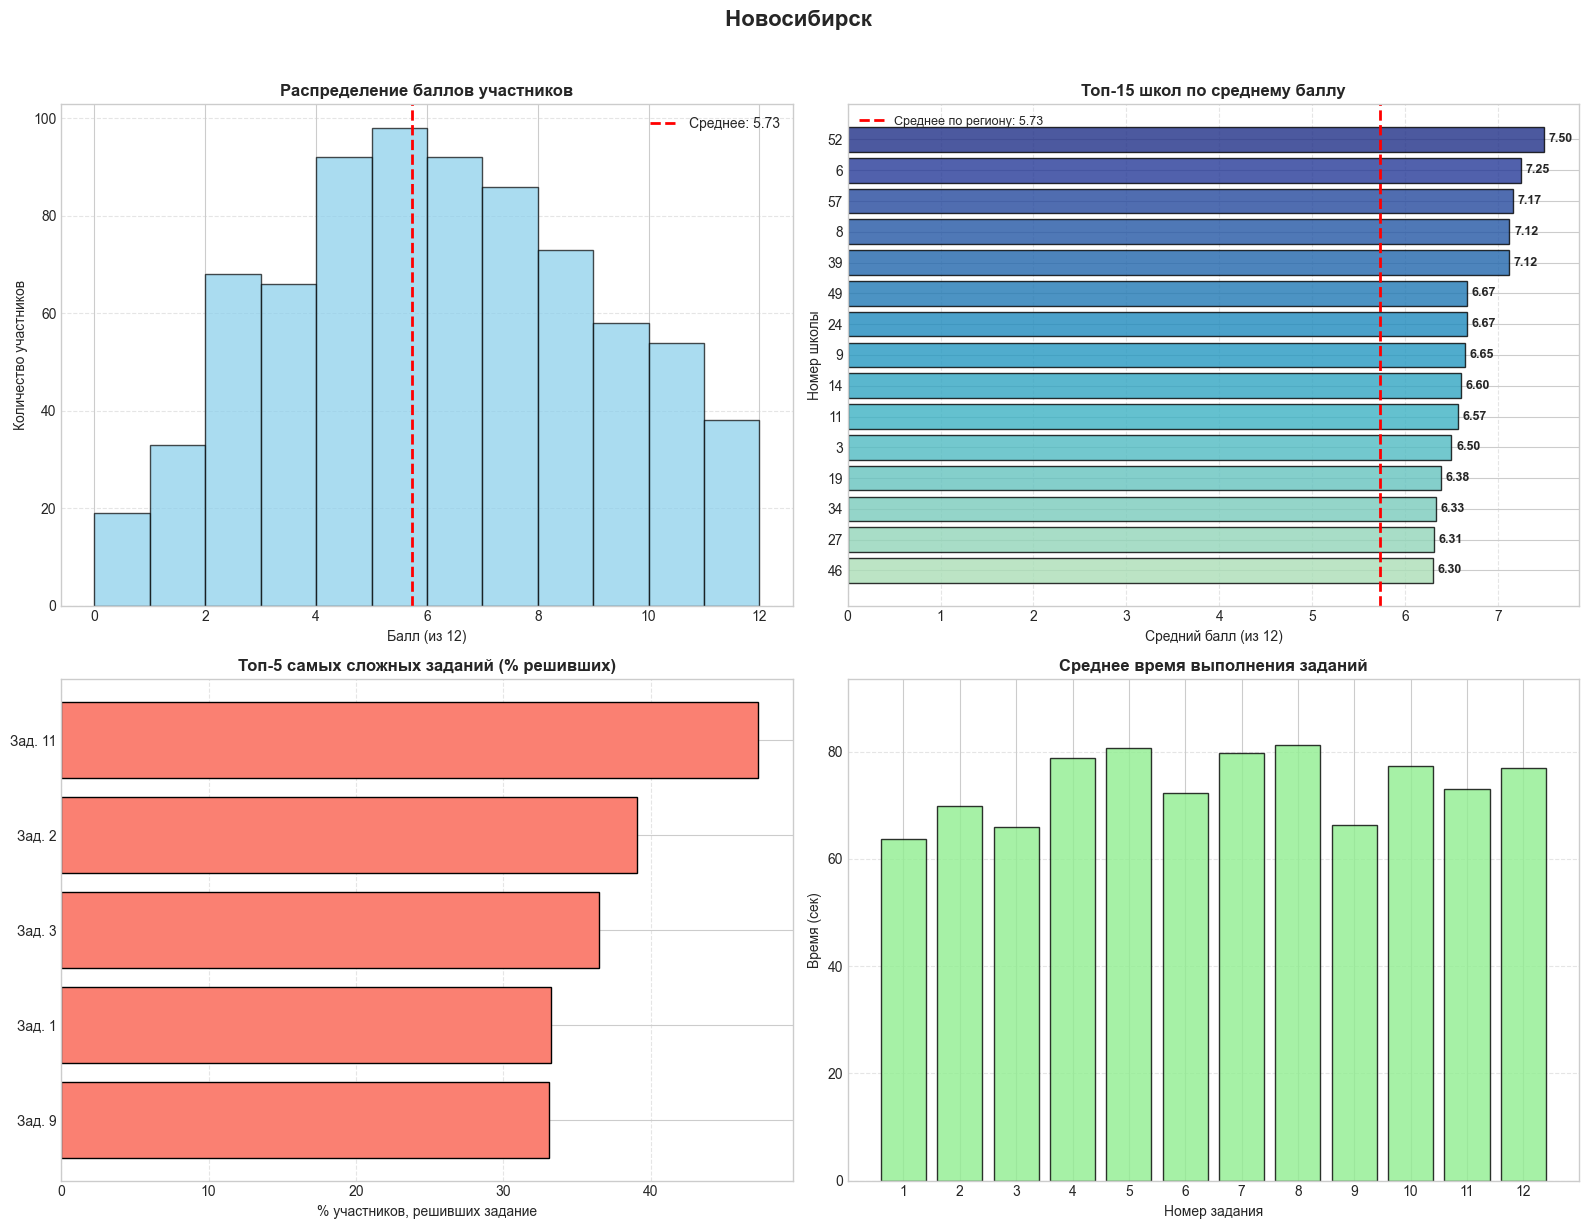

АНАЛИЗ РЕГИОНА: ПЕРМЬ
 Всего участников: 757


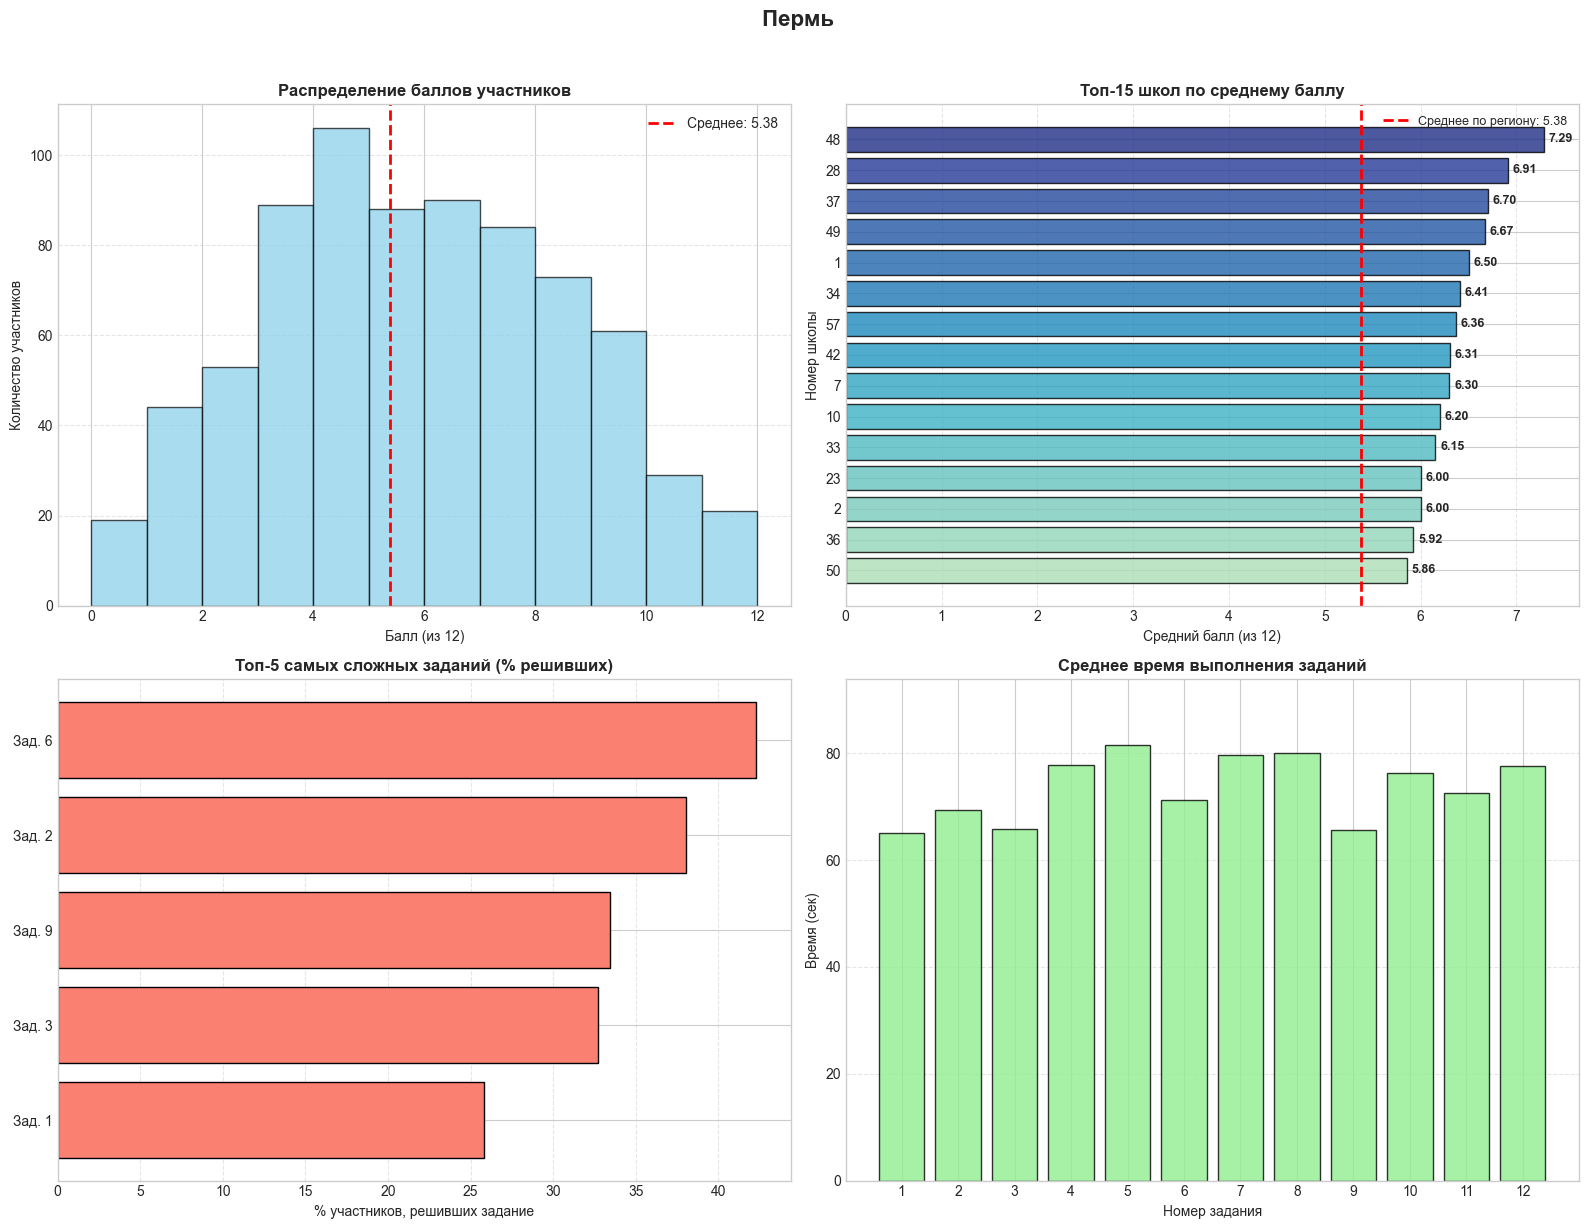

АНАЛИЗ РЕГИОНА: РОСТОВ-НА-ДОНУ
 Всего участников: 787


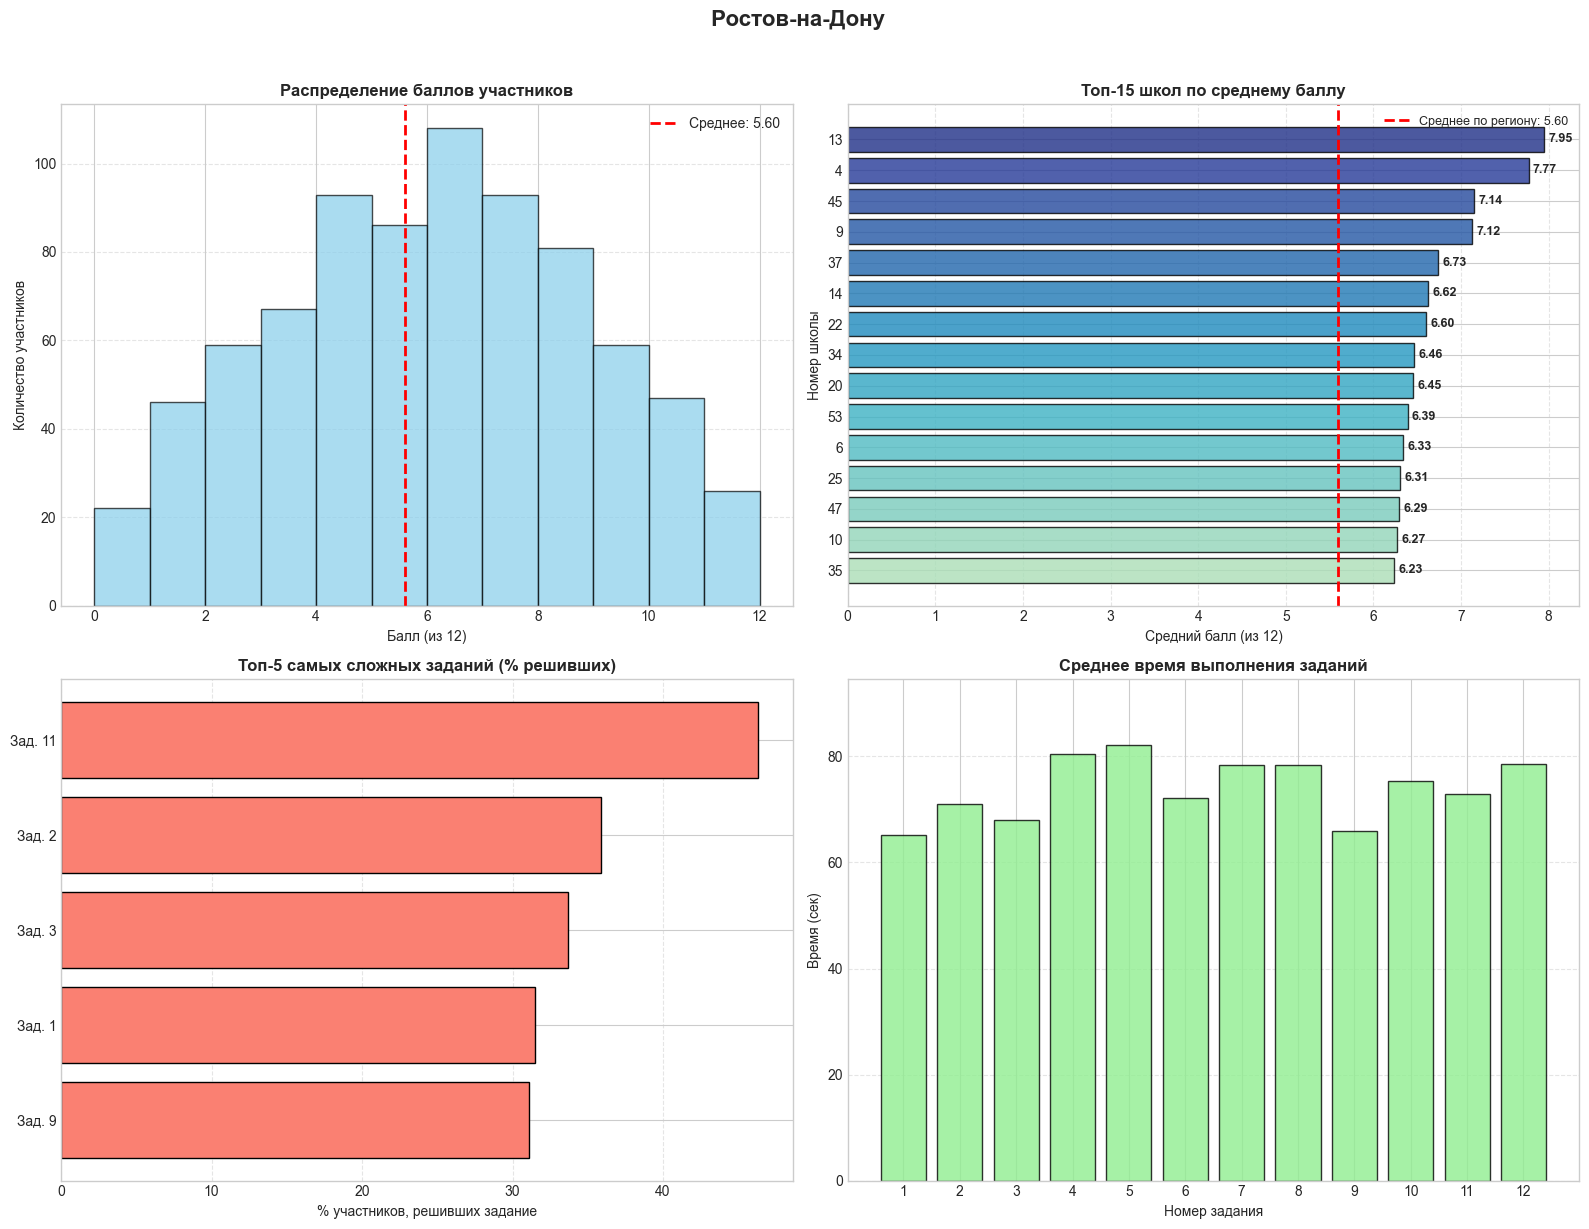

АНАЛИЗ РЕГИОНА: САНКТ-ПЕТЕРБУРГ
 Всего участников: 796


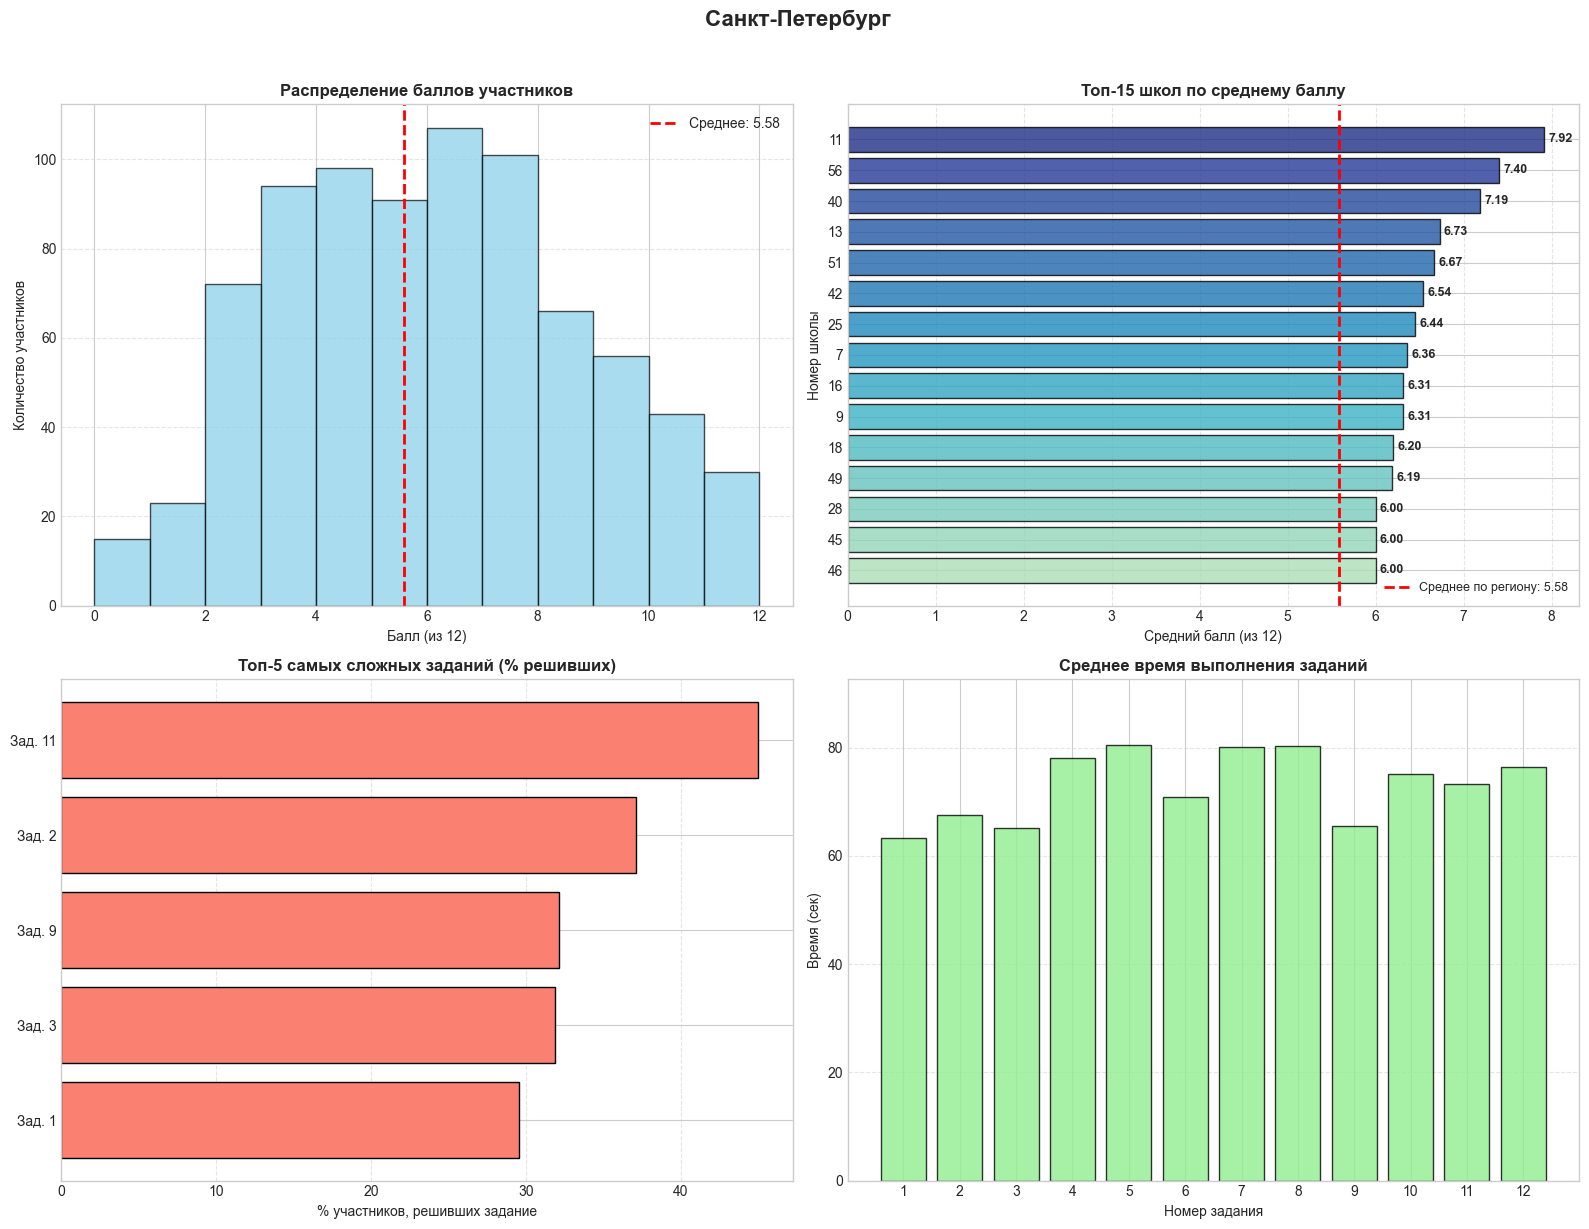

АНАЛИЗ РЕГИОНА: УФА
 Всего участников: 838


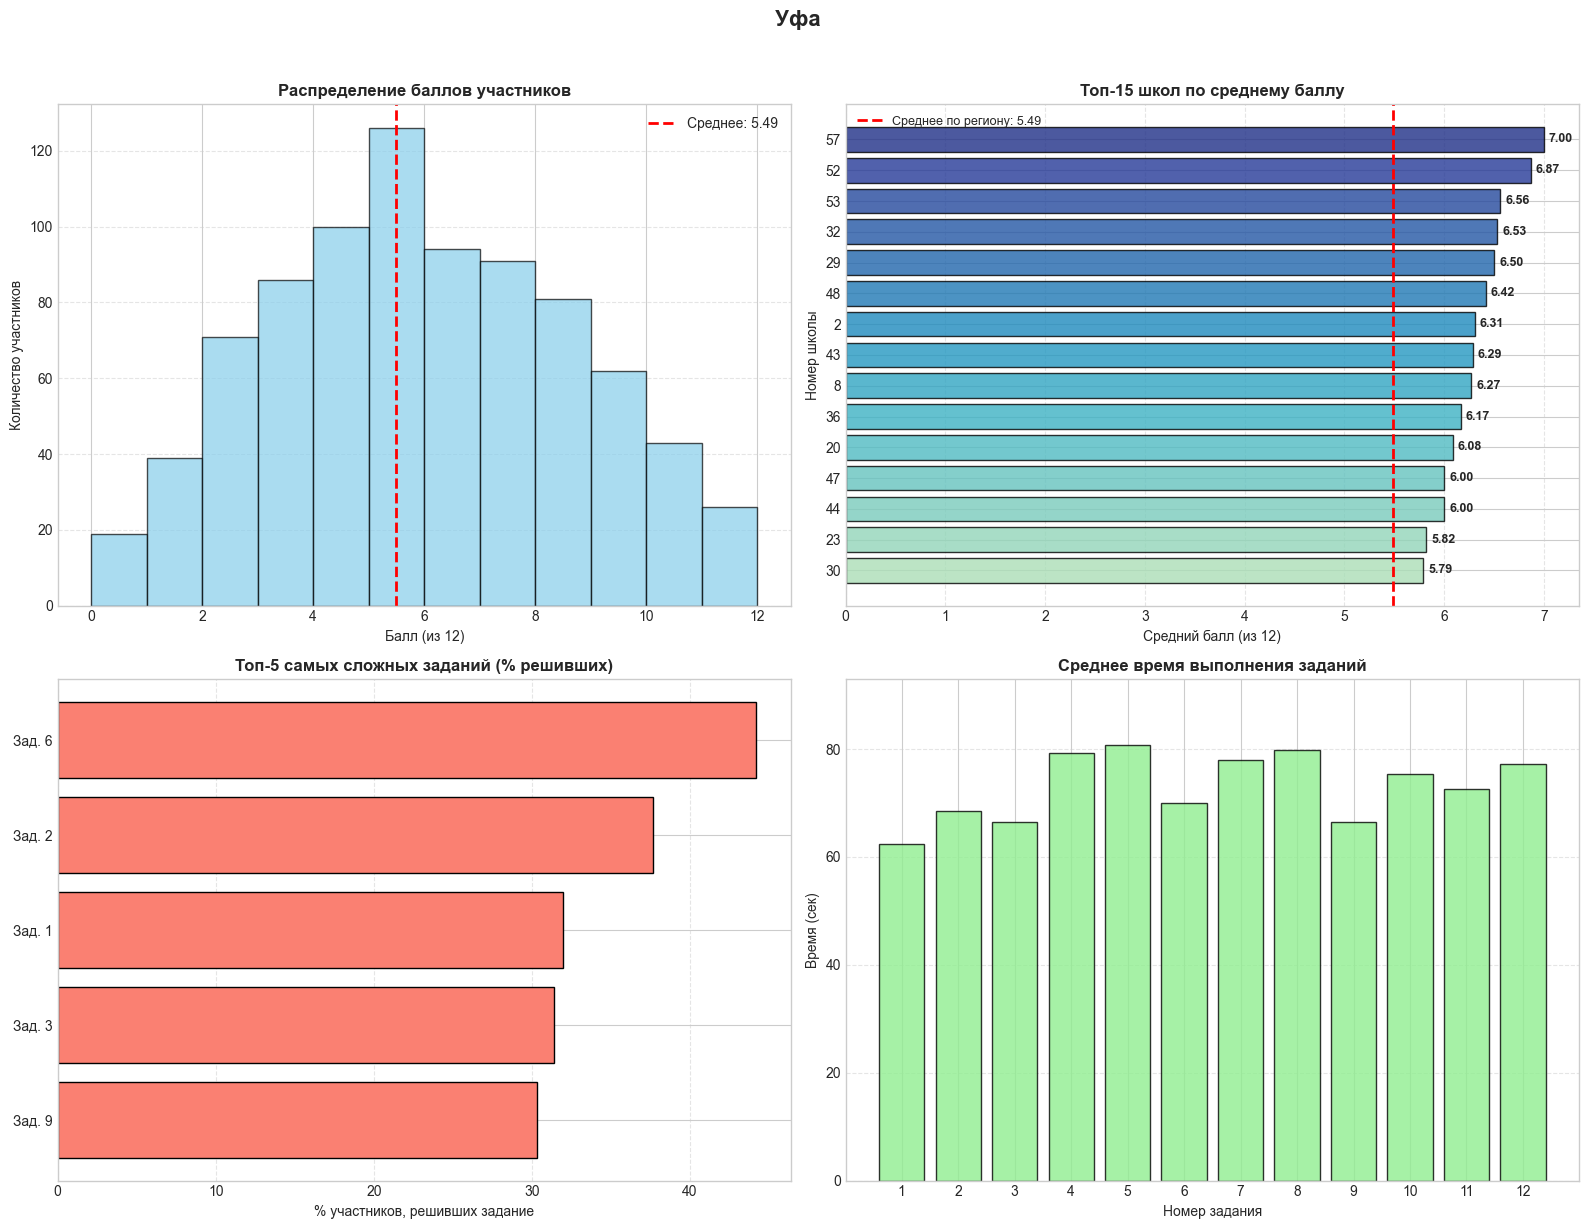

In [194]:
#ГРАФИКИ ДЛЯ ВСЕХ РЕГИОНОВ 

def build_region_dashboard(region):
    
   
    region_df = df[df['region'] == region].copy()
    
   
    print(f"АНАЛИЗ РЕГИОНА: {region.upper()}")
    print(f" Всего участников: {len(region_df)}")
    
   
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle(f' {region}', fontsize=16, fontweight='bold', y=1.02)
    
    
    ax1 = axes[0, 0]
    region_df['total_score'].hist(bins=12, edgecolor='black', alpha=0.7, ax=ax1, color='skyblue')
    ax1.axvline(region_df['total_score'].mean(), color='red', linestyle='--', linewidth=2, 
                label=f'Среднее: {region_df["total_score"].mean():.2f}')
    ax1.set_title('Распределение баллов участников', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Балл (из 12)')
    ax1.set_ylabel('Количество участников')
    ax1.legend()
    ax1.grid(axis='y', linestyle='--', alpha=0.5)
    

    ax2 = axes[0, 1]
    
    
    school_stats = region_df.groupby('school_number').agg(
        avg_score=('total_score', 'mean'),
        count=('total_score', 'count')
    ).reset_index()
    
   
    school_stats = school_stats.sort_values('avg_score', ascending=True)
    
   
    if len(school_stats) > 15:
        school_stats = school_stats.tail(15)
        ax2.set_title('Топ-15 школ по среднему баллу', fontsize=12, fontweight='bold')
    else:
        ax2.set_title('Средний балл по школам', fontsize=12, fontweight='bold')
    
    
    colors = plt.cm.YlGnBu(np.linspace(0.3, 0.9, len(school_stats)))
    
    bars = ax2.barh(
        school_stats['school_number'].astype(str), 
        school_stats['avg_score'],
        color=colors,
        edgecolor='black',
        alpha=0.8
    )
    
   
    for i, (idx, row) in enumerate(school_stats.iterrows()):
        ax2.text(row['avg_score'] + 0.05, i, f"{row['avg_score']:.2f}", 
                 va='center', fontsize=9, fontweight='bold')
    
    ax2.set_xlabel('Средний балл (из 12)', fontsize=10)
    ax2.set_ylabel('Номер школы', fontsize=10)
    
    
    ax2.axvline(region_df['total_score'].mean(), color='red', linestyle='--', 
                linewidth=2, label=f'Среднее по региону: {region_df["total_score"].mean():.2f}')
    ax2.legend(fontsize=9)
    ax2.grid(axis='x', linestyle='--', alpha=0.5)
    
    ax3 = axes[1, 0]
    
    task_difficulty = []
    for i in range(1, 13):
        correct_col = f'Task_{i}_correct'
        time_col = f'Task_{i}_time_spent'
        valid = region_df[region_df[time_col] > 0]
        if len(valid) > 0:
            solve_rate = valid[correct_col].mean() * 100
            task_difficulty.append({'task': f'Зад. {i}', 'solve_rate': solve_rate})
    
    diff_df = pd.DataFrame(task_difficulty).sort_values('solve_rate', ascending=True).head(5)
    
    ax3.barh(diff_df['task'], diff_df['solve_rate'], color='salmon', edgecolor='black')
    ax3.set_title('Топ-5 самых сложных заданий (% решивших)', fontsize=12, fontweight='bold')
    ax3.set_xlabel('% участников, решивших задание')
    ax3.grid(axis='x', linestyle='--', alpha=0.5)
    
  
    ax4 = axes[1, 1]
    
    task_numbers = list(range(1, 13))
    avg_times = []
    
    for i in task_numbers:
        time_col = f'Task_{i}_time_spent'
        valid = region_df[region_df[time_col] > 0]
        if len(valid) > 0:
            avg_times.append(valid[time_col].mean())
        else:
            avg_times.append(0)
    
    ax4.bar(task_numbers, avg_times, color='lightgreen', edgecolor='black', alpha=0.8)
    ax4.set_title('Среднее время выполнения заданий', fontsize=12, fontweight='bold')
    ax4.set_xlabel('Номер задания')
    ax4.set_ylabel('Время (сек)')
    ax4.set_xticks(task_numbers)
    ax4.set_ylim(0, max(avg_times) * 1.15)
    ax4.grid(axis='y', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()



for reg in sorted(df['region'].unique()):
    build_region_dashboard(reg)
    plt.show()

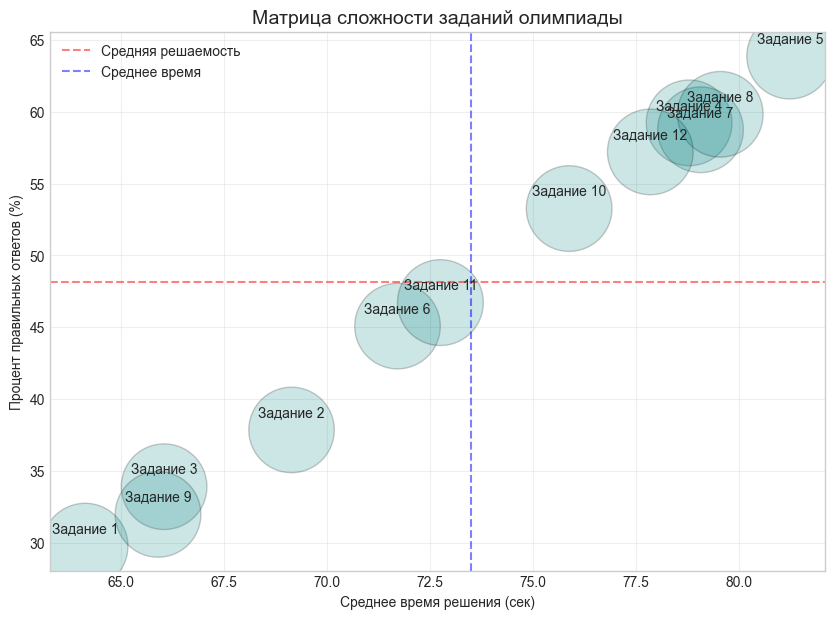

In [159]:
import matplotlib.pyplot as plt

tasks_stats = []
for i in range(1, 13):
    t_col = f'Task_{i}_time_spent'
    c_col = f'Task_{i}_correct'
    
    # Только те, кто вообще пытался решать
    valid = df[df[t_col] > 0]
    if len(valid) > 0:
        tasks_stats.append({
            'task': f'Задание {i}',
            'avg_time': valid[t_col].mean(),
            'solve_rate': valid[c_col].mean() * 100,
            'attempts': len(valid)
        })

tasks_df = pd.DataFrame(tasks_stats)

plt.figure(figsize=(10, 7))
plt.scatter(tasks_df['avg_time'], tasks_df['solve_rate'], 
            s=tasks_df['attempts']/2, alpha=0.2, c='teal', edgecolors='black')


for i, row in tasks_df.iterrows():
    plt.annotate(row['task'], (row['avg_time'], row['solve_rate']), textcoords="offset points", xytext=(0,10), ha='center')

plt.axhline(tasks_df['solve_rate'].mean(), color='red', linestyle='--', alpha=0.5, label='Средняя решаемость')
plt.axvline(tasks_df['avg_time'].mean(), color='blue', linestyle='--', alpha=0.5, label='Среднее время')

plt.title('Матрица сложности заданий олимпиады', fontsize=14)
plt.xlabel('Среднее время решения (сек)')
plt.ylabel('Процент правильных ответов (%)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [188]:
# Группируем по школам и считаем метрики
school_stats = df.groupby('school_number').agg(
    avg_score=('total_score', 'mean'),
    region=('region', lambda x: x.mode()[0]),  
    participants=('student_id', 'count')        
).reset_index()

top_10_schools = school_stats.sort_values('avg_score', ascending=False).head(10)

print(" Топ-10 школ по среднему баллу:")
print("=" * 50)
for i, (_, row) in enumerate(top_5_schools.iterrows(), 1):
    print(f"  {i}. Школа {int(row['school_number'])} ({row['region']}) — средний балл: {row['avg_score']:.2f} (участников: {int(row['participants'])})")

 Топ-10 школ по среднему баллу:
  1. Школа 13 (Пермь) — средний балл: 6.12 (участников: 137)
  2. Школа 53 (Екатеринбург) — средний балл: 6.01 (участников: 135)
  3. Школа 14 (Уфа) — средний балл: 5.94 (участников: 119)
  4. Школа 24 (Пермь) — средний балл: 5.90 (участников: 138)
  5. Школа 6 (Москва) — средний балл: 5.89 (участников: 150)
  6. Школа 49 (Санкт-Петербург) — средний балл: 5.88 (участников: 133)
  7. Школа 22 (Москва) — средний балл: 5.81 (участников: 150)
  8. Школа 48 (Казань) — средний балл: 5.81 (участников: 120)
  9. Школа 40 (Санкт-Петербург) — средний балл: 5.81 (участников: 156)
  10. Школа 34 (Уфа) — средний балл: 5.80 (участников: 158)


 АНАЛИЗ СРЕДНЕГО БАЛЛА ПО КЛАССАМ

 Общий средний балл по олимпиаде: 5.55
 Всего участников: 7928



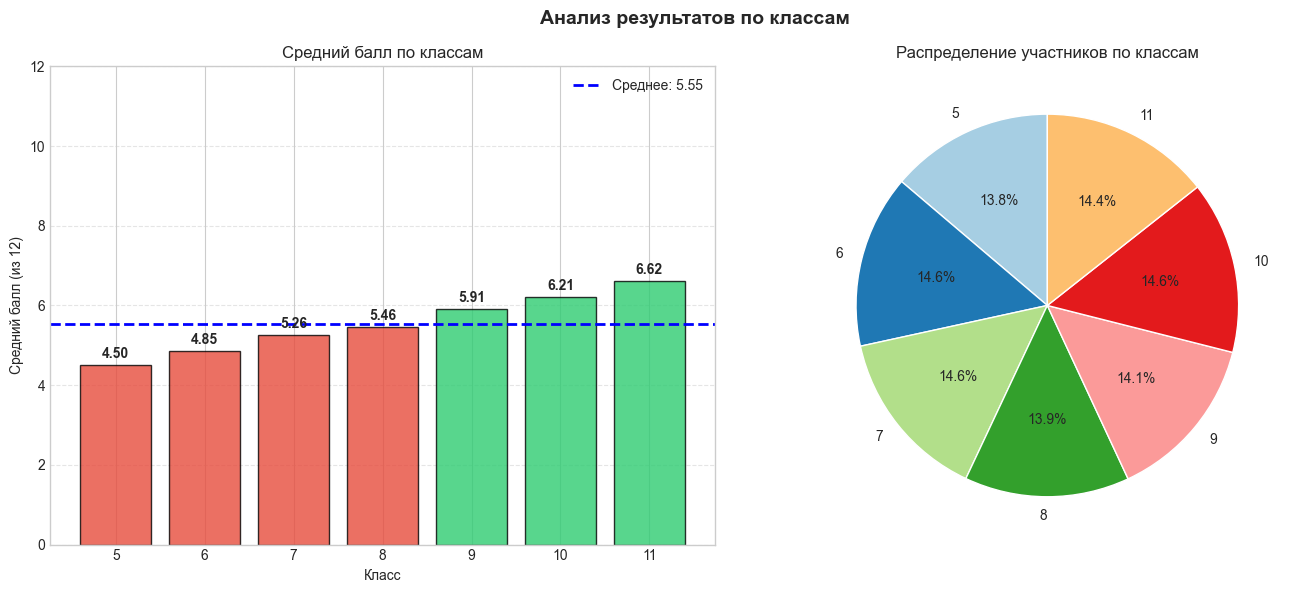

 ВЫВОДЫ:
Лучший результат: 11 класс (средний балл 6.62)
Самый слабый результат: 5 класс (средний балл 4.50)
Самая активная аудитория: 6 класс (14.6% всех участников)


In [192]:
#ОБЩИЙ АНАЛИЗ ПО КЛАССАМ 
def analyze_scores_by_grade():
    
    grade_stats = df.groupby('grade').agg(
        avg_score=('total_score', 'mean'),
        median_score=('total_score', 'median'),
        participants=('total_score', 'count')
    ).reset_index()
    
   
    total_participants = len(df)
    grade_stats['share'] = (grade_stats['participants'] / total_participants * 100).round(1)
    
   
    overall_avg = df['total_score'].mean()
    
    

    print(" АНАЛИЗ СРЕДНЕГО БАЛЛА ПО КЛАССАМ")
    print(f"\n Общий средний балл по олимпиаде: {overall_avg:.2f}")
    print(f" Всего участников: {total_participants}\n")
    
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('Анализ результатов по классам', fontsize=14, fontweight='bold')
    
    
    ax1 = axes[0]
    colors = ['#2ecc71' if x >= overall_avg else '#e74c3c' for x in grade_stats['avg_score']]
    
    bars = ax1.bar(grade_stats['grade'].astype(str), grade_stats['avg_score'], 
                   color=colors, edgecolor='black', alpha=0.8)
    
    ax1.axhline(overall_avg, color='blue', linestyle='--', linewidth=2, 
                label=f'Среднее: {overall_avg:.2f}')
    
    
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.1,
                f'{height:.2f}', ha='center', va='bottom', fontweight='bold')
    
    ax1.set_title('Средний балл по классам', fontsize=12)
    ax1.set_xlabel('Класс')
    ax1.set_ylabel('Средний балл (из 12)')
    ax1.set_ylim(0, 12)
    ax1.legend()
    ax1.grid(axis='y', linestyle='--', alpha=0.5)
    
   
    ax2 = axes[1]
    ax2.pie(grade_stats['participants'], labels=grade_stats['grade'].astype(str),
            autopct='%1.1f%%', colors=plt.cm.Paired.colors, startangle=90)
    ax2.set_title('Распределение участников по классам', fontsize=12)
    
    plt.tight_layout()
    plt.show()
    
    
    best_grade = grade_stats.loc[grade_stats['avg_score'].idxmax()]
    worst_grade = grade_stats.loc[grade_stats['avg_score'].idxmin()]
    most_active = grade_stats.loc[grade_stats['participants'].idxmax()]
    
    print(" ВЫВОДЫ:")
    print(f"Лучший результат: {int(best_grade['grade'])} класс "
          f"(средний балл {best_grade['avg_score']:.2f})")
    print(f"Самый слабый результат: {int(worst_grade['grade'])} класс "
          f"(средний балл {worst_grade['avg_score']:.2f})")
    print(f"Самая активная аудитория: {int(most_active['grade'])} класс "
          f"({most_active['share']:.1f}% всех участников)")

analyze_scores_by_grade()